# Lab 07: The Periodic Quasar

**ASTR 457, Fall 2026, posted Thu Oct 22, due Wed Oct 28 by Noon (fork → PR, as always)**

Today we looked at time series and Gaussian processes. "I found a period" is one of the most-retracted sentences in astronomy, because a periodic claim is only as good as your model of the noise, and quasar noise is not white.

A survey team monitoring quasars in the g band reports a tentative periodic modulation in one of them. A quasar whose brightness repeats could be two supermassive black holes in orbit. Each of you has a quasar: `data/<your netid>.csv`, with columns `t_days` (days since the first epoch), `mag_g` and `sigma_mag` (the pipeline's per-epoch uncertainty, which you can trust). Three observing seasons over about 970 days, 240 to 290 epochs.

Quasars vary all the time with no period at all. Their light curves are well described by a **damped random walk** (DRW): the next value is a decayed copy of the last one plus a random kick. It is a Gaussian process with the exponential covariance function

$$k(\Delta t) = \sigma^2\,\exp\!\left(-\frac{|\Delta t|}{\tau}\right),$$

where $\sigma$ is the rms variability in magnitudes and $\tau$ is the damping time in days, how long the light curve remembers where it was.

I generated your light curve, so I know $\sigma$ and $\tau$, and whether there is a periodic signal in it. For some of you there isn't, and "no evidence" is then the right answer. Your $\sigma$ and $\tau$ are graded against the truth in units of your own error bar, so don't sandbag the error bar either: a 68% interval on $\ln\tau$ wider than $3\times$ the reference width I compute for your dataset (same prior as Part 2, or the profile likelihood) is capped. For the periodicity question I grade the evidence you present, not only the verdict.

Use whatever tools you like, including AI assistants, and document it in Part 6. You may be selected to defend this lab orally.

Weights: Part 1 10%, Part 2 30%, Part 3 20%, Part 4 25%, Part 5 5%, Part 6 10%.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
from scipy.optimize import minimize
from scipy.linalg import cho_factor, cho_solve
from astropy.timeseries import LombScargle
from scipy.signal import find_peaks

NETID = 'acm18'   # <-- set this
d = np.genfromtxt(f'{NETID}.csv', delimiter=',', names=True)
t, y, e = d['t_days'], d['mag_g'], d['sigma_mag']
T = t.max() - t.min()
print(f"{t.size} epochs over {T:.0f} days; median quoted error {np.median(e):.3f} mag; rms of the light curve {y.std():.3f} mag")

258 epochs over 965 days; median quoted error 0.041 mag; rms of the light curve 0.217 mag


## Part 1: Look first, then the periodogram and its window (10%)

Plot the light curve with its error bars, and look at it. Then compute a Lomb-Scargle periodogram (`astropy.timeseries.LombScargle`, using the errors) over periods from 20 days to $T/2$, where $T$ is the length of your light curve, on a frequency grid no coarser than $1/(5T)$. Compute the **window function**, the periodogram of the sampling alone: `LombScargle(t, np.ones_like(y), fit_mean=False, center_data=False)`, scaled to the same maximum as your periodogram (only the peak positions mean anything). Plot both. Report the highest peak and astropy's `false_alarm_probability` for it.

Answer in a few sentences: what period is the highest peak, which other peaks are probably aliases of it or of the sampling, why not search beyond $T/2$, and what noise model does astropy's false-alarm probability assume?


Text(0, 0.5, 'mag')

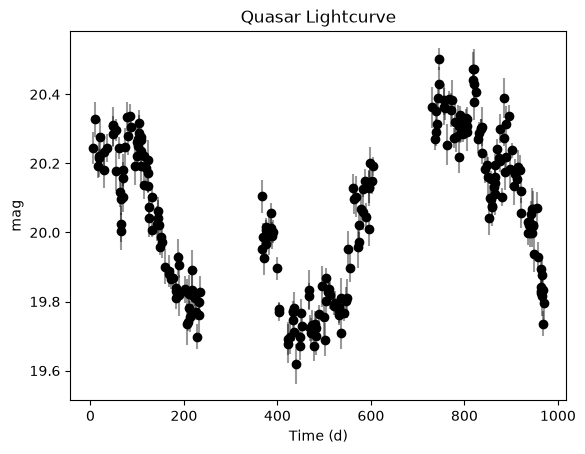

In [2]:
# Part 1: your work here
plt.scatter(t,y,c='k')
plt.errorbar(t,y,yerr=e,fmt = '|', alpha = .4,  c = 'k')
plt.title('Quasar Lightcurve');plt.xlabel('Time (d)');plt.ylabel('mag')

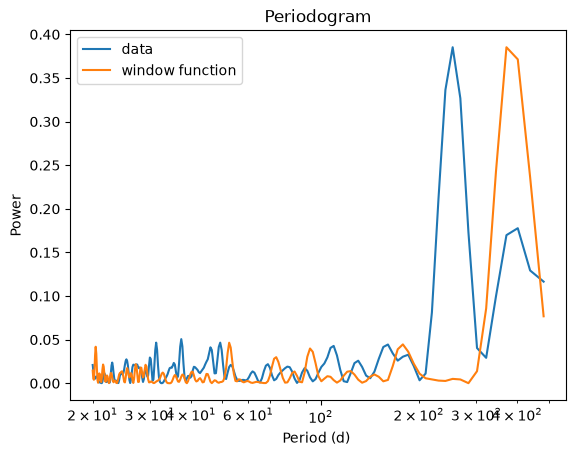

In [3]:
T = t.max() - t.min()
ls = LombScargle(t,y,e)
frequency, power = ls.autopower(minimum_frequency=2/T, maximum_frequency=1/20, samples_per_peak = 5)
wfreq, wpower = LombScargle(t, np.ones_like(y), fit_mean=False, center_data=False).autopower(minimum_frequency=2/T, maximum_frequency=1/20, samples_per_peak = 5)

wpower *= power.max()/wpower.max()

plt.plot(1/frequency, power, label = 'data')
plt.plot(1/wfreq,wpower,label = 'window function')
plt.title('Periodogram');plt.xlabel('Period (d) ');plt.ylabel('Power');plt.legend()
plt.xscale('log')

In [4]:
peak_idx = np.argmax(power)

best_frequency = frequency[peak_idx]
best_period = 1 / best_frequency
best_power = power[peak_idx]

print("Best period =", best_period, "days")
print("Peak power =", best_power)
print("False alarm probability =", ls.false_alarm_probability(best_power))

Best period = 253.82921052631573 days
Peak power = 0.38520409491012503
False alarm probability = 7.65731029014577e-24


**ANSWER (a few sentences):**

The period with the highest peak is at 253.83 days, it looks to have an alias at ~126.915 days which looks to be the 4th most prominent peak. The second highest peak ~370 days looks to be an alias of sampling, it aligns with the highest window fucntion peak and corresponds to roughly a year. At 185 days you can see the 5th highest peak correspond to the window function reprisenting half a year. If we were searching beyond $T/2$ the periodogram would be picking up on signals that it couldn't contrain. Any period longer than $T/2$ would not have time to complete a cycle within the data I have. The false alarm probabilities are conducted with a null hypothesis of no periodic component, it does not say anything about if a peak is real or the correct peak and does not distinguish with sampling periods evident in the window funtction.


## Part 2: The Gaussian process (30%)

Model the light curve as a constant mean $\mu$ plus a DRW plus the measurement noise. The data $\mathbf{y}$ are one draw from a multivariate Gaussian,

$$\ln L = -\tfrac12 (\mathbf{y}-\mu)^T C^{-1} (\mathbf{y}-\mu) - \tfrac12 \ln|C| - \tfrac{N}{2}\ln 2\pi, \qquad C_{ij} = \sigma^2 e^{-|t_i-t_j|/\tau} + \sigma_i^2\,\delta_{ij},$$

where $\sigma_i$ is the quoted error of epoch $i$ and $\sigma$ without a subscript is the DRW amplitude. $N$ is about 250, so one likelihood evaluation is milliseconds with a Cholesky factorization.

1. Write the log-likelihood, log-prior and log-posterior for $(\mu, \ln\sigma, \ln\tau)$. Use priors uniform in $\ln\sigma$ and $\ln\tau$, bounded to $0.01 < \sigma < 3$ mag and $10 < \tau < 4000$ d, justify each in a line, and say what the bound on $\tau$ does to your result.
2. Find the maximum-likelihood point from more than one starting value, and say why. Then get uncertainties on $\sigma$ and $\tau$ with `emcee` (you know how from Lab 05; say how you checked convergence) or with a profile likelihood over $\tau$ (maximize over $\mu$ and $\sigma$ at each $\tau$ on a grid from 10 to 4000 d; the interval is where $\Delta(-2\ln L) = 1$). Report $\sigma$ and $\tau$ as medians with 68% intervals (or best fit with a profile interval), and $T/\tau$. The $\tau$ interval won't be symmetric; report it as it is, and say what makes $\tau$ hard to measure from a light curve this long.
3. Refit with a squared-exponential kernel, $k = \sigma^2 e^{-\Delta t^2/2\ell^2}$ (same number of parameters). Which has the higher maximum $\ln L$, by how much, and what does that say about how smooth a quasar light curve is?
4. Plot the posterior-mean prediction and its 68% band for your best kernel on a regular time grid spanning one seasonal gap, with the data. Say whether your band is for the latent light curve or for a new measurement, and why that matters against data points.
5. Hold out four non-overlapping blocks of 30 consecutive days, each inside one observing season and at least 60 days apart (random, fixed seed, redraw until they satisfy that). Fit on the rest, predict the held-out points, and compare them with the band that includes the measurement noise. Report the number held out, the fraction inside the 68% band, and the $R^2$ of the predictions against the training mean. Do the same for the other kernel. Does the band look reasonable?

#### Hints:
- get $\ln|C|$ from the diagonal of the Cholesky factor (`scipy.linalg.cho_factor`, `cho_solve`), never from `np.linalg.det`
- a few thousand `emcee` steps is enough and takes a few minutes; ten thousand is not needed
- with about 40 held-out points the fraction inside the band scatters by roughly $\pm 7\%$, so judge it accordingly

**FINAL ANSWER:** $\sigma = $ _0.40_ (+_0.36_ / −_0.16_) mag, $\tau = $ _535.15_ (+_1446.55_ / −_354.97_) d, $T/\tau = $ _1.802_; the exponential kernel beats the squared exponential by $\Delta\ln L = $ _29.37_; _37_ of _48_ held-out points are inside the 68% band.


In [5]:
# Part 2: your work here

def log_likelihood(p, t, y, e):
    mu, lnsig, lntau = p
    sig = np.exp(lnsig)
    tau = np.exp(lntau)
    dt = np.abs(t[:, None] - t[None, :])
    # DRW covariance matrix
    C = sig**2 * np.exp(-dt/tau)
    # add measurement noise
    C += np.diag(e**2)
    r = y - mu
    # Cholesky factorization
    cho = cho_factor(C)
    # (y-mu)^T C^-1 (y-mu)
    chi2 = r @ cho_solve(cho, r)
    # log|C|
    logdet = 2*np.sum(np.log(np.diag(cho[0])))
    N = len(y)
    return -0.5 * (chi2 + logdet + N*np.log(2*np.pi))

def log_prior(p, p0=None):
    mu, lnsig, lntau = p

    sig = np.exp(lnsig)
    tau = np.exp(lntau)

    if sig <= 0.01 or sig >= 3:
        return -np.inf

    if tau <= 10 or tau >= 4000:
        return -np.inf

    return 0.0


def log_posterior(p, t, y, e):
    lp = log_prior(p)

    if not np.isfinite(lp):
        return -np.inf

    return lp + log_likelihood(p, t, y, e)


For $\ln\sigma$ I adopted a uniform prior that constrains $\sigma$ from being 0 or exibiting variability much larger than what is seen in my data.

For $\ln\tau$ I adopted a uniform prior where the lower bound excludes variability faster than sampling could account for and the upper bound prevents timescales much larger than the lightcurve baseline from dominating the fit. If the best fit tau is above my upper bound the posterior will clump against the boundary, if tau is very small this effect would not be present.

In [6]:
def neg_log_likelihood(p,t,y,e):
    return -log_likelihood(p,t,y,e)

results = []

for sig0 in [0.03,0.1,0.3,1.0]:
    for tau0 in [20,100,500,2000]:

        p0 = np.array([np.mean(y),np.log(sig0),np.log(tau0)])

        result = minimize(neg_log_likelihood,p0,args=(t,y,e),method='Nelder-Mead',options=dict(maxiter=20000,xatol=1e-6,fatol=1e-6))

        if result.success:
            results.append((log_likelihood(result.x,t,y,e),result.x))

results.sort(key=lambda x:x[0],reverse=True)

best_logL,best_p = results[0]

print('best lnL =',best_logL)
print('best fit =',best_p)


best lnL = 350.02001305737735
best fit = [20.04976485 -1.51963536  5.06371571]


This best fit has the largest lnL value meaning of all off the minima explored by my for loop this sead found the lowest minima making it the best place to start MCMC

mu: tau = 47.7
lnsig: tau = 52.6
lntau: tau = 52.0
Minimum chain/tau = 57.1


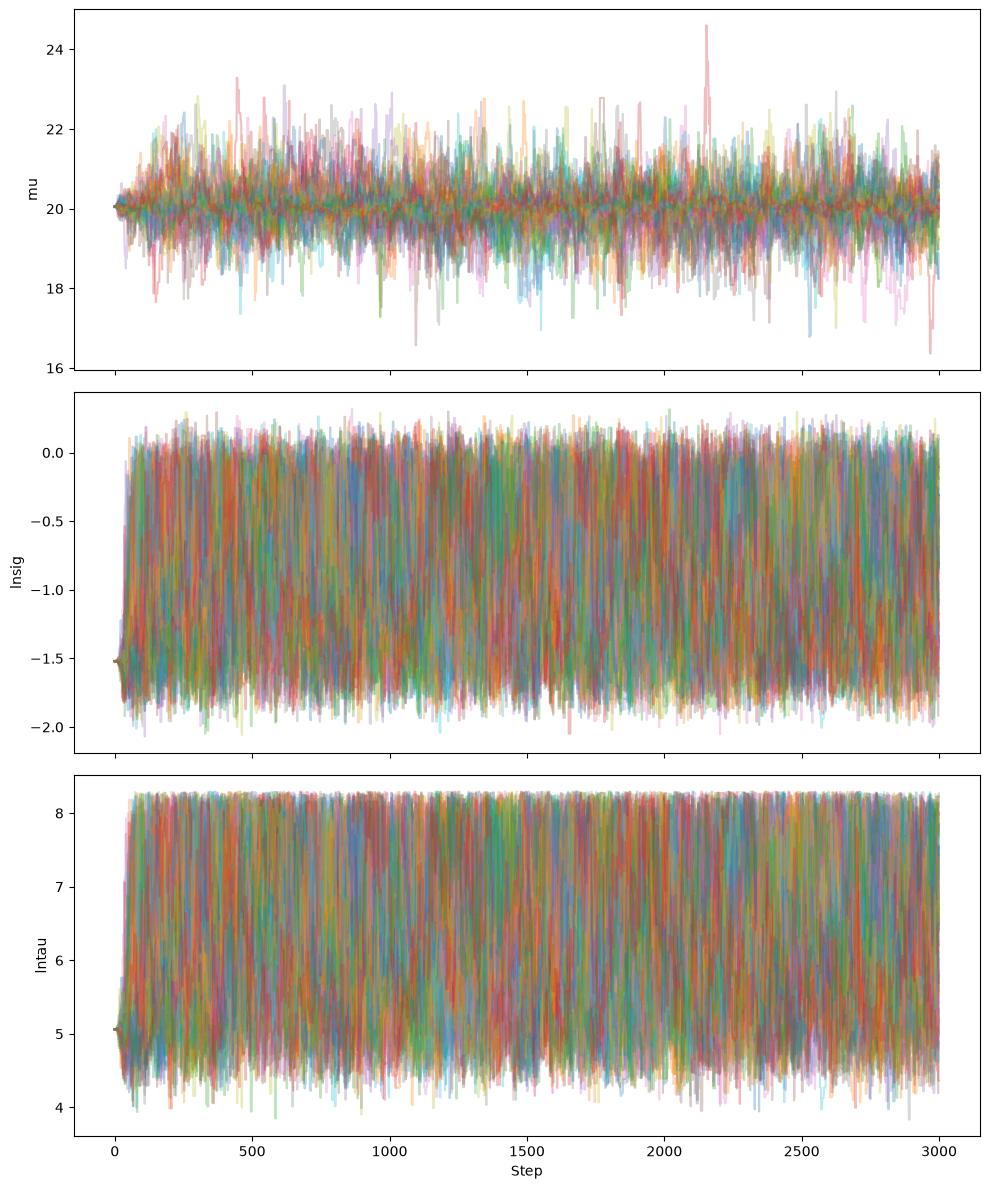

In [7]:
'''emcee'''
# --------------------------------------------------
# Initialize walkers
# --------------------------------------------------

nwalkers = 64
ndim = len(best_p)
nsteps = 3000
rng = np.random.default_rng(10252026)

scale = 1e-4*np.maximum(np.abs(best_p),1)
pos = best_p + rng.normal(0,scale,size=(nwalkers,ndim))

sampler = emcee.EnsembleSampler(nwalkers,ndim,log_posterior,args=(t,y,e))
sampler.run_mcmc(pos,nsteps,progress=False)

names = ['mu', 'lnsig', 'lntau']

try:
    tau = sampler.get_autocorr_time()
    for name,x in zip(names,tau):
        print(f'{name}: tau = {x:.1f}')
    print(f'Minimum chain/tau = {nsteps/np.max(tau):.1f}')
except emcee.autocorr.AutocorrError as err:
    print('Autocorrelation time could not be reliably estimated.')
    print(err)

chain = sampler.get_chain()

fig,axes = plt.subplots(ndim,1,figsize=(10,12),sharex=True)

for i in range(ndim):
    axes[i].plot(chain[:,:,i],alpha=0.3)
    axes[i].set_ylabel(names[i])

axes[-1].set_xlabel('Step')
plt.tight_layout()
plt.show()

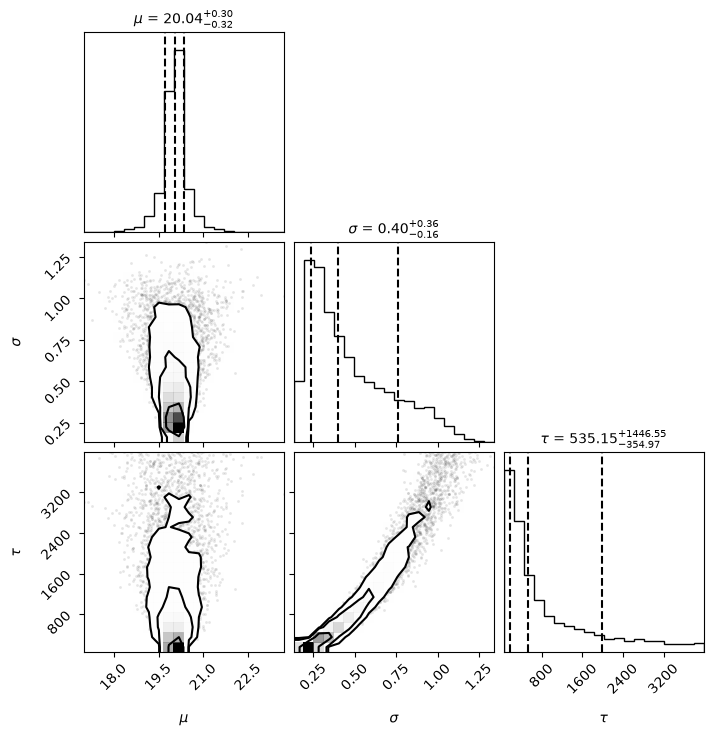

In [8]:
import corner

burnin = int(3*np.max(tau))
thin = max(1,int(np.max(tau)/2))

samples = sampler.get_chain(discard=burnin,thin=thin,flat=True)

mu_s = samples[:,0]
lnsig_s = samples[:,1]
lntau_s = samples[:,2]

sig_s = np.exp(lnsig_s)
tau_s = np.exp(lntau_s)

physical_samples = np.column_stack((mu_s,sig_s,tau_s))

labels = [r'$\mu$',r'$\sigma$',r'$\tau$']

fig = corner.corner(physical_samples,labels=labels,show_titles=True,quantiles=[0.16,0.5,0.84],
                    title_fmt='.2f',title_kwargs={'fontsize':10})
plt.show()


In [9]:
T/np.quantile(tau_s,.5)

np.float64(1.8023806476037745)

##### Exponential Kernel Results

$\sigma = $ _0.40_ (+_0.36_ / −_0.16_) mag, $\tau = $ _535.15_ (+_1446.55_ / −_354.97_) d, $T/\tau = $ _1.802_

$\tau$ is hard to measure on this lightcurve this long because $T/\tau$ is only 1.799 meaning the light curve spans fewer than two damping timescales. With only a small number of indeprendent correlation times observed a wide range of $\tau$ values produce similar variability patterns. 

In [10]:
def squared_log_likelihood(p, t, y, e):
    mu, lnsig, lntau = p
    sig = np.exp(lnsig)
    tau = np.exp(lntau)
    dt = t[:, None] - t[None, :]
    # DRW covariance matrix
    C = sig**2 * np.exp(-dt**2/(2*tau**2))
    # add measurement noise
    C += np.diag(e**2)
    r = y - mu
    # Cholesky factorization
    cho = cho_factor(C)
    # (y-mu)^T C^-1 (y-mu)
    chi2 = r @ cho_solve(cho, r)
    # log|C|
    logdet = 2*np.sum(np.log(np.diag(cho[0])))
    N = len(y)
    return -0.5 * (chi2 + logdet + N*np.log(2*np.pi))


def neg_squared_log_likelihood(p,t,y,e):
    return -squared_log_likelihood(p,t,y,e)

sq_results = []

for sig0 in [0.03,0.1,0.3,1.0]:
    for tau0 in [20,100,500,2000]:

        p0 = np.array([np.mean(y),np.log(sig0),np.log(tau0)])

        sq_result = minimize(neg_squared_log_likelihood,p0,args=(t,y,e),method='Nelder-Mead',options=dict(maxiter=20000,xatol=1e-6,fatol=1e-6))

        if sq_result.success:
            sq_results.append((squared_log_likelihood(sq_result.x,t,y,e),sq_result.x))

sq_results.sort(key=lambda x:x[0],reverse=True)

sq_best_logL,sq_best_p = sq_results[0]


print('DRW lnL =',best_logL)
print('SE  lnL =',sq_best_logL)

delta_logL = best_logL - sq_best_logL

print('Delta lnL =',delta_logL)

DRW lnL = 350.02001305737735
SE  lnL = 320.6473327076301
Delta lnL = 29.37268034974727


 Which has the higher maximum $\ln L$, by how much, and what does that say about how smooth a quasar light curve is?

 The DRW method provided a higher $\ln L$ by 29.37 which is strong support for the DRW kernel. This hints that the quasar light curve is too rough to be modeled with the squared exponent kernel and is not very smooth.

In [11]:
mu0 = np.median(mu_s)
sig0 = np.median(sig_s)
tau0 = np.median(tau_s)

gaps = np.diff(t)
i = np.argmax(gaps)

gap_start = t[i]
gap_end = t[i+1]

tgrid = np.linspace(gap_start-75,gap_end+75,500)

dt = np.abs(t[:,None]-t[None,:])
C = sig0**2*np.exp(-dt/tau0)
C += np.diag(e**2)

dt_star = np.abs(tgrid[:,None]-t[None,:])
Kstar = sig0**2*np.exp(-dt_star/tau0)

dt_grid = np.abs(tgrid[:,None]-tgrid[None,:])
Kss = sig0**2*np.exp(-dt_grid/tau0)

cho = cho_factor(C)

r = y-mu0

pred_mean = mu0 + Kstar@cho_solve(cho,r)

pred_cov = Kss - Kstar@cho_solve(cho,Kstar.T)

pred_std = np.sqrt(np.clip(np.diag(pred_cov),0,None))

(159.003, 441.905)

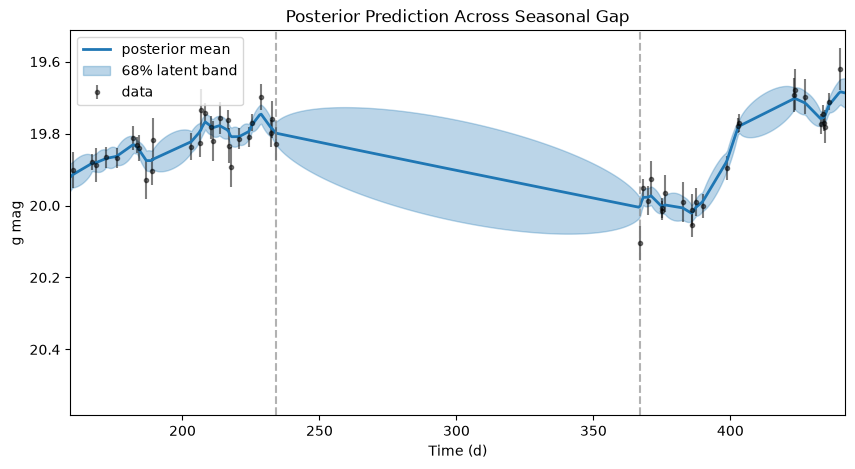

In [12]:
plt.figure(figsize=(10,5))

plt.errorbar(t,y,yerr=e,fmt='.',c='k',alpha=.5,label='data')
plt.plot(tgrid,pred_mean,c='tab:blue',lw=2,label='posterior mean')
plt.fill_between(tgrid,pred_mean-pred_std,pred_mean+pred_std,color='tab:blue',alpha=.3,label='68% latent band')

plt.axvline(gap_start,c='gray',ls='--',alpha=.6)
plt.axvline(gap_end,c='gray',ls='--',alpha=.6)

plt.gca().invert_yaxis()
plt.title('Posterior Prediction Across Seasonal Gap');plt.xlabel('Time (d)');plt.ylabel('g mag')
plt.legend()
plt.xlim(gap_start-75,gap_end+75)

This shaded region is the 68% for the latent lightcurve describing the true brightness. Notably this plotted line does not include measurment error so it would not be effective in predicting measurments taken during this timeframe. A region that could predict measurments would end up being larger than this one

In [13]:
'''DRW'''
rng = np.random.default_rng(457)

season_breaks = np.where(np.diff(t)>60)[0]
edges = np.r_[0,season_breaks+1,len(t)]

starts = []

for a,b in zip(edges[:-1],edges[1:]):
    season_t = t[a:b]
    for s in season_t:
        if np.sum((season_t>=s)&(season_t<s+30))>0 and s+30<season_t.max():
            starts.append(s)

while True:
    block_starts = rng.choice(starts,4,replace=False)
    if np.min(np.abs(block_starts[:,None]-block_starts[None,:])[np.triu_indices(4,1)])>=60:
        break

hold_mask = np.zeros(len(t),dtype=bool)

for s in block_starts:
    hold_mask |= (t>=s)&(t<s+30)

train_mask = ~hold_mask

In [14]:
ttr,ytr,etr = t[train_mask],y[train_mask],e[train_mask]
tte,yte,ete = t[hold_mask],y[hold_mask],e[hold_mask]

results = []

for sig0 in [0.03,0.1,0.3,1.0]:
    for tau0 in [20,100,500,2000]:

        p0 = np.array([np.mean(ytr),np.log(sig0),np.log(tau0)])

        res = minimize(neg_log_likelihood,p0,args=(ttr,ytr,etr),method='Nelder-Mead')

        if res.success:
            results.append((log_likelihood(res.x,ttr,ytr,etr),res.x))

results.sort(key=lambda x:x[0],reverse=True)

cv_logL,cv_p = results[0]

mu,sig,tau = cv_p[0],np.exp(cv_p[1]),np.exp(cv_p[2])

In [15]:
dt = np.abs(ttr[:,None]-ttr[None,:])
C = sig**2*np.exp(-dt/tau)
C += np.diag(etr**2)

dt_star = np.abs(tte[:,None]-ttr[None,:])
Kstar = sig**2*np.exp(-dt_star/tau)

dt_test = np.abs(tte[:,None]-tte[None,:])
Kss = sig**2*np.exp(-dt_test/tau)

cho = cho_factor(C)

r = ytr-mu

pred_mean = mu + Kstar@cho_solve(cho,r)

pred_cov = Kss - Kstar@cho_solve(cho,Kstar.T)

pred_std = np.sqrt(np.clip(np.diag(pred_cov),0,None))

pred_std_meas = np.sqrt(pred_std**2 + ete**2)

inside = np.abs(yte-pred_mean)<=pred_std_meas

frac_inside = inside.mean()

r2 = 1 - np.sum((yte-pred_mean)**2)/np.sum((yte-np.mean(ytr))**2)

print('DRW Kernal')
print('held out =',len(yte))
print('fraction in 68% band =',frac_inside)
print('R^2 =',r2)

DRW Kernal
held out = 48
fraction in 68% band = 0.7708333333333334
R^2 = 0.938447216948296


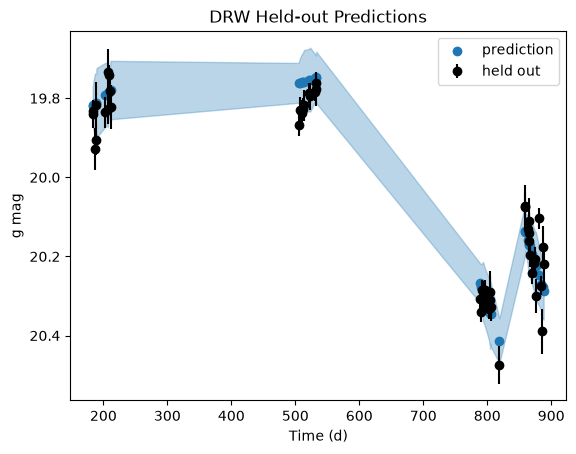

In [16]:
plt.errorbar(tte,yte,yerr=ete,fmt='o',c='k',label='held out')
plt.scatter(tte,pred_mean,c='tab:blue',label='prediction')
plt.fill_between(tte,pred_mean-pred_std_meas,pred_mean+pred_std_meas,color='tab:blue',alpha=.3)
plt.gca().invert_yaxis()
plt.title('DRW Held-out Predictions');plt.xlabel('Time (d)');plt.ylabel('g mag')
plt.legend()

Squared Error Kernal
held out = 48
fraction in 68% band = 0.9375
R^2 = 0.854464305749568


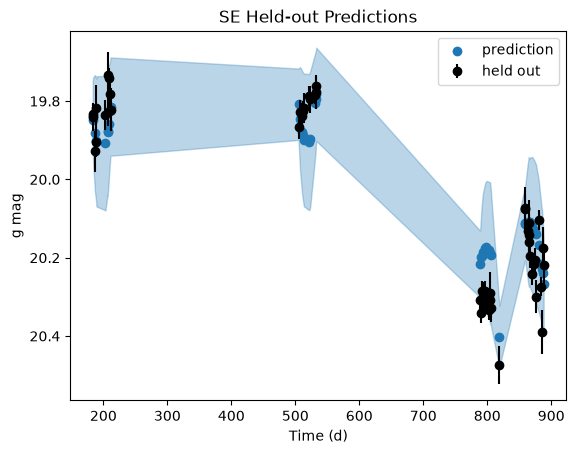

In [17]:
'''Squared error'''
results = []

for sig0 in [0.03,0.1,0.3,1.0]:
    for tau0 in [20,100,500,2000]:

        p0 = np.array([np.mean(ytr),np.log(sig0),np.log(tau0)])

        sq_res = minimize(neg_squared_log_likelihood,p0,args=(ttr,ytr,etr),method='Nelder-Mead')

        if sq_res.success:
            sq_results.append((squared_log_likelihood(sq_res.x,ttr,ytr,etr),sq_res.x))

sq_results.sort(key=lambda x:x[0],reverse=True)

sq_logL,sq_p = sq_results[0]

sqmu,sqsig,sqtau = sq_p[0],np.exp(sq_p[1]),np.exp(sq_p[2])

sqC = sqsig**2*np.exp(-dt/sqtau)
sqC += np.diag(etr**2)

sqKstar = sqsig**2*np.exp(-dt_star/sqtau)

sqKss = sqsig**2*np.exp(-dt_test/sqtau)

sqcho = cho_factor(sqC)

sqr = ytr-sqmu

sqpred_mean = sqmu + sqKstar@cho_solve(sqcho,sqr)

sqpred_cov = sqKss - sqKstar@cho_solve(sqcho,sqKstar.T)

sqpred_std = np.sqrt(np.clip(np.diag(sqpred_cov),0,None))

sqpred_std_meas = np.sqrt(sqpred_std**2 + ete**2)

sqinside = np.abs(yte-sqpred_mean)<=sqpred_std_meas

sqfrac_inside = sqinside.mean()

sqr2 = 1 - np.sum((yte-sqpred_mean)**2)/np.sum((yte-np.mean(ytr))**2)

print('Squared Error Kernal')
print('held out =',len(yte))
print('fraction in 68% band =',sqfrac_inside)
print('R^2 =',sqr2)

plt.errorbar(tte,yte,yerr=ete,fmt='o',c='k',label='held out')
plt.scatter(tte,sqpred_mean,c='tab:blue',label='prediction')
plt.fill_between(tte,sqpred_mean-sqpred_std_meas,sqpred_mean+sqpred_std_meas,color='tab:blue',alpha=.3)
plt.gca().invert_yaxis()
plt.title('SE Held-out Predictions');plt.xlabel('Time (d)');plt.ylabel('g mag')
plt.legend()

**FINAL ANSWER:** *fill in the numbers above, here, in your own words*

For the fitted values usingh emcee I fond that $\sigma = $ _0.39_ (+_0.36_ / −_0.16_) mag, $\tau = $ _535.89_ (+_1443.74_ / −_356.16_) d, $T/\tau = $ _1.799_. When comparing the DRW kenral to the squared error kernal I found that drw had a larger maximum likelyhood by ~$29.73$ meaning that the lightcurve is not as smooth as needed to be modeled with the square error kernal. When fitting the different kernals on partial data and comparing it on sets of holdouts I recover again that the DRW method has the most reasonable band. SE has too large of errors and this effect is visible in the R2 value.

## Part 3: Is it periodic? (20%)

The question is whether the highest peak is too tall to be noise, so the answer depends on the noise model.

1. Before you run anything in this part, write in a markdown cell above your code the empirical $p$-value below which you would claim a period, and why. No changing it afterwards.
2. Simulate at least 1000 DRW light curves with your Part 2 maximum-likelihood $\mu$, $\sigma$ and $\tau$, at your epochs and with your errors: $\mathbf{y} = \mu + L\mathbf{z} + $ noise, with $L$ the Cholesky factor of the DRW covariance, $\mathbf{z}$ standard normal, and a Gaussian draw with each $\sigma_i$. Run the same Lomb-Scargle search (20 d to $T/2$) on every one, record the highest peak in each, and report the fraction whose highest peak is at least as tall as yours. That is your empirical $p$-value. Compare it with astropy's false-alarm probability from Part 1 and explain the difference.
3. Fit $y = \mu + A\sin(2\pi t/P + \phi) + \mathrm{DRW}$. For fixed $\sigma$, $\tau$ (the Part 2 maximum-likelihood values; say how your $p$-value changes at the two ends of your $\tau$ interval) and a fixed period, the amplitudes enter linearly, so $\hat\theta = (X^T C^{-1} X)^{-1} X^T C^{-1}\mathbf{y}$ with columns $1, \cos 2\pi t/P, \sin 2\pi t/P$. Scan the period from 20 d to $T/2$, record the best $\Delta\chi^2$ against the constant-mean model, and compare it with the same statistic on your simulated light curves (the simulations are what account for the look-elsewhere effect).
4. Is there evidence for a periodic signal, by your own rule? If yes, give a period and an amplitude with uncertainties; if no, say what you would need to see. One sentence: should the team announce a binary candidate on this evidence?

#### Hints:
- 300 simulations cannot resolve a $p$-value of 0.01


Before performing anyanlysis I will set my p-value threshould at p-value <= 0.05 corresponding to 5% which is defined to be statistically unusual.

In [18]:
# Part 3: your work here
nsim = 1000

mu0 = best_p[0]
sig0 = np.exp(best_p[1])
tau0 = np.exp(best_p[2])

dt = np.abs(t[:,None]-t[None,:])

C = sig0**2*np.exp(-dt/tau0)

L = np.linalg.cholesky(C + 1e-10*np.eye(len(t)))

rng = np.random.default_rng(10272026)

max_powers = np.zeros(nsim)

for i in range(nsim):

    z = rng.normal(size=len(t))

    ysim = mu0 + L@z + rng.normal(0,e)

    freq_sim,power_sim = LombScargle(t,ysim,e).autopower(minimum_frequency=2/T,maximum_frequency=1/20,samples_per_peak=5)

    max_powers[i] = power_sim.max()

p_emp0 = np.mean(max_powers >= best_power)

print('Observed peak power =',best_power)
print('Empirical p-value =',p_emp0)

Observed peak power = 0.38520409491012503
Empirical p-value = 0.432


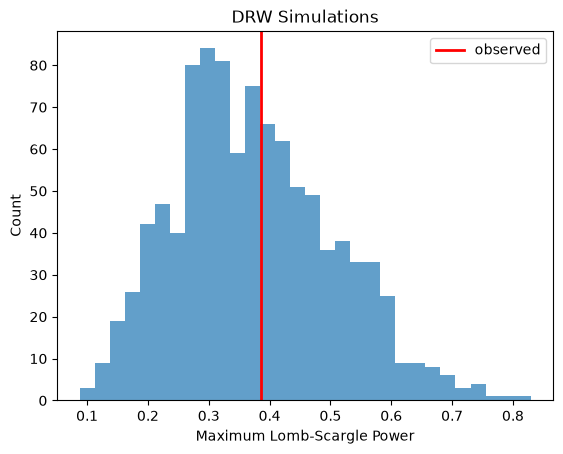

In [19]:
plt.hist(max_powers,bins=30,alpha=.7)
plt.axvline(best_power,c='r',lw=2,label='observed')
plt.xlabel('Maximum Lomb-Scargle Power')
plt.ylabel('Count')
plt.title('DRW Simulations')
plt.legend()

My empirical p-value is 0.432 when compared to the Lomb Scargle FAP of 7.65731029014577e-24 this is a significant deviation. The difference here is that my empirical p-value comes from sampling many different DRW lines and comparing my period to theirs where the FAP compares the power of the period to a flat line with noise. Lomb Scargle is not aware of the context of the lightcurve and just knows that something is there, the empirical value knows how often a feature like that can randomly happen on this model and lables it as not very surprizing.

Best period = 24.164644144144145
Best Δχ² = 7.830706324914729
Empirical p-value = 0.765


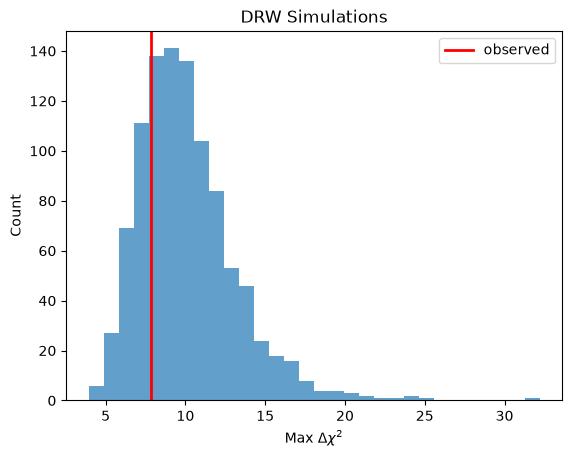

In [20]:
mu0 = best_p[0]
sig0 = np.exp(best_p[1])
tau0 = np.exp(best_p[2])

dt = np.abs(t[:,None]-t[None,:])

C = sig0**2*np.exp(-dt/tau0)
C += np.diag(e**2)

cho = cho_factor(C)

X0 = np.ones((len(t),1))

mu_hat = np.linalg.solve(
    X0.T@cho_solve(cho,X0),
    X0.T@cho_solve(cho,y)
)

r0 = y-X0@mu_hat

chi2_null = r0@cho_solve(cho,r0)

periods = np.linspace(20,T/2,1000)

delta_chi2 = np.zeros(len(periods))

for i,P in enumerate(periods):

    X = np.column_stack([np.ones_like(t),np.cos(2*np.pi*t/P),np.sin(2*np.pi*t/P)])

    theta = np.linalg.solve(X.T@cho_solve(cho,X),X.T@cho_solve(cho,y))

    r = y-X@theta

    chi2_periodic = r@cho_solve(cho,r)

    delta_chi2[i] = chi2_null-chi2_periodic

best_delta_chi2 = delta_chi2.max()
best_period = periods[np.argmax(delta_chi2)]

print('Best period =',best_period)
print('Best Δχ² =',best_delta_chi2)

L = np.linalg.cholesky(sig0**2*np.exp(-dt/tau0)+1e-10*np.eye(len(t)))

rng = np.random.default_rng(457)

sim_delta_chi2 = np.zeros(1000)

for j in range(1000):

    ysim = mu0 + L@rng.normal(size=len(t)) + rng.normal(0,e)

    theta0 = np.linalg.solve(X0.T @ cho_solve(cho,X0),X0.T @ cho_solve(cho,ysim))

    r0 = ysim - X0 @ theta0

    chi2_null_sim = r0 @ cho_solve(cho,r0)
    best_sim = 0

    for P in periods:

        X = np.column_stack([np.ones_like(t),
                             np.cos(2*np.pi*t/P),
                             np.sin(2*np.pi*t/P)])

        theta = np.linalg.solve(
            X.T@cho_solve(cho,X),
            X.T@cho_solve(cho,ysim)
        )

        r = ysim-X@theta

        chi2_periodic = r@cho_solve(cho,r)

        best_sim = max(best_sim,chi2_null_sim-chi2_periodic)

    sim_delta_chi2[j] = best_sim

p_emp = np.mean(sim_delta_chi2>=best_delta_chi2)

print('Empirical p-value =',p_emp)

plt.hist(sim_delta_chi2,bins=30,alpha=.7)
plt.axvline(best_delta_chi2,c='r',lw=2,label='observed')
plt.xlabel(r'Max $\Delta\chi^2$')
plt.ylabel('Count')
plt.title('DRW Simulations')
plt.legend()


**ANSWER (the decision rule first, then the verdict):**

My rule to determine if there is a period in this light curve is if the p-value for the determined best period from Lomb Scargle is deemed unusual pvalue <= 5%. 

On my data there is no evidence for a periodic signal. For there to be one I would need it to prove that it is significantly larger than the periodic like data in a population of simulated DRWs. The team should not announce evience of a binary.

## Part 4: The referee report (25%)

`ai_solution.ipynb` in this directory is a complete analysis of this exact problem by an AI assistant. It runs top to bottom without errors. It is also wrong in at least **three** distinct, substantive ways (style and cosmetics don't count; "it used 5-fold cross-validation and I used four blocks" is not a finding by itself).

Write a referee report:

1. Identify at least three substantive statistical errors.
2. Demonstrate each one on your dataset: show, with a number or a plot, what the error does to the inference. A demonstration can come out negative: if an error does not move your numbers, show that and say what it would take for it to bite.
3. State the correct treatment (you built most of it in Parts 2 and 3).

You know the drill by now.


##### Identify 

1. Trust Lomb Scargle Period; Uses the reported FAP without considering the random variations in a quasars lightcurve and how that FAP is calculated
2. Does not compare periodogram with window function to rule out sampling periods.
3. Using the wrong Gaussian Process kernel; The AI declares the light curve is smooth and uses the squared exponent kernel without validating that claim

##### Demonstrait

In [21]:
# Part 4: your work here
'''Trusting Lomb Scargle'''
print("False alarm probability =", ls.false_alarm_probability(best_power))
print('Empirical p-value =',p_emp0)

False alarm probability = 7.65731029014577e-24
Empirical p-value = 0.432


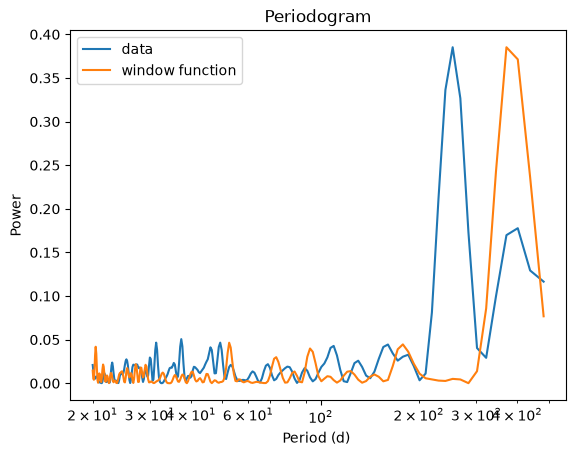

In [22]:
'''Using a Window Function'''

plt.plot(1/frequency, power, label = 'data')
plt.plot(1/wfreq,wpower,label = 'window function')
plt.title('Periodogram');plt.xlabel('Period (d) ');plt.ylabel('Power');plt.legend()
plt.xscale('log')

DRW Kernal
fraction in 68% band = 0.7708333333333334
R^2 = 0.938447216948296



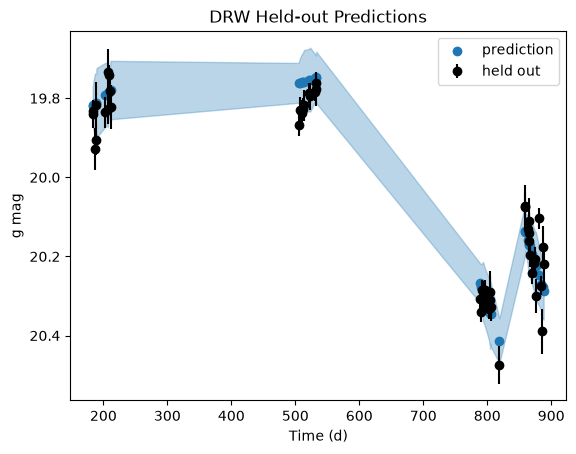

Squared Error Kernal
fraction in 68% band = 0.9375
R^2 = 0.854464305749568


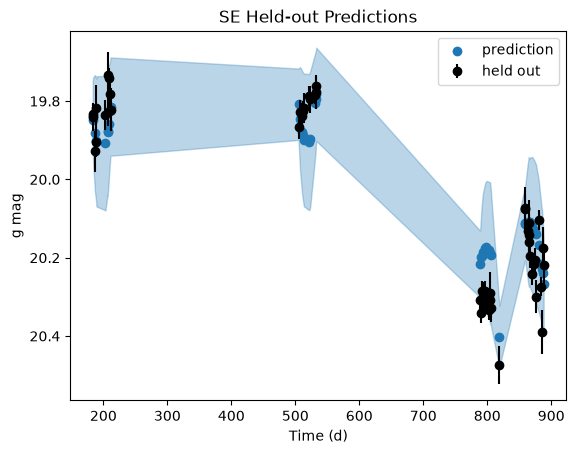

In [23]:
'''Using the wrong Gaussian Kernel'''

print('DRW Kernal')
print('fraction in 68% band =',frac_inside)
print('R^2 =',r2)
print()
plt.figure()
plt.errorbar(tte,yte,yerr=ete,fmt='o',c='k',label='held out')
plt.scatter(tte,pred_mean,c='tab:blue',label='prediction')
plt.fill_between(tte,pred_mean-pred_std_meas,pred_mean+pred_std_meas,color='tab:blue',alpha=.3)
plt.gca().invert_yaxis()
plt.title('DRW Held-out Predictions');plt.xlabel('Time (d)');plt.ylabel('g mag')
plt.legend()
plt.show()

print('Squared Error Kernal')
print('fraction in 68% band =',sqfrac_inside)
print('R^2 =',sqr2)

plt.figure()
plt.errorbar(tte,yte,yerr=ete,fmt='o',c='k',label='held out')
plt.scatter(tte,sqpred_mean,c='tab:blue',label='prediction')
plt.fill_between(tte,sqpred_mean-sqpred_std_meas,sqpred_mean+sqpred_std_meas,color='tab:blue',alpha=.3)
plt.gca().invert_yaxis()
plt.title('SE Held-out Predictions');plt.xlabel('Time (d)');plt.ylabel('g mag')
plt.legend()
plt.show()

**REFEREE REPORT:**

##### State

###### Trusting Lomb Scargle

The AI trusts the Lomb Scargle Period because the returned false alarm probability is essencially 0. What it fails to consider is that the FAP value is calculated comparing the actual data to a flat line with gaussian noise, not a random walk light curve. The proper treatment is to find the empirical p-value by comparing the power of the chosen period peak to the most prominent peaks found in many samples generated from a DRW conditioned on the provided data. This allows the pvalue to reprisent how likely is this period given a damped random walk, not a flat line. After doing this you find a pvalue of 0.432 which hints at no strong evidence of there being a periodic signal.

###### Using a window function

The AI fails to check the periodogram with a window function before declaring the largest peak is a true periodic signal. In reality there are many parts of observing that can show up as noise in a periodogram like the observing schedule. In the plot above we can clearly see that some of the most prominent peaks of periodogram correspond to the window funciton. The proper treatment is to compare the periodogram to a window function to rule out periods from sampling effects.

###### Using the wrong gaussian process kernel

In this lab I investigated the differences between performing a Gausian Process with a Squared error and a DRW kernel. There were a few different reasons why I chose DRW but the plots above demonstrait why I wouldn't choose Squared Error. The AI claims that "Quasar variability on these time scales is smooth, so we model it with a squared-exponential kernel" but it has no way of garunteeing that on this set of data. 

In the plots above we see how the different models perform on held data it was not conditioned with. The DRW performs similar to what you'd expect containing ~77% of the held data within 1$\sigma$ error bars and a $\chi^2$ of 0.938. The Squared error contained 93% of the data in its error bars and returned a $\chi^2$ of 0.854. This drop in $\chi^2$ and increase of contained variables is not a measure of the models performance but more a reflection of overly large error bars. This can be seen clearly in the plots where the DRW shaded region tightly follows the plotted points but the Squared error shaded region is large and fills a much larger part of the graph. This is a direct efect of the assumption of the lightcurve being smooth negatively effecting the Squared Error Kernel, sandbagging the errors does not mean the model constrained the true values. The correct treatment in this situation is to compare the two kernels and pick the one that performed, for this data DRW is the kernel to choose.

## Part 5: A live light curve (5%)

Everything so far was a light curve I simulated. This one is real and recent. Look up your quasar in `data/live_objects.csv` (columns `netid`, `ztf_oid`). The function below pulls its g-band light curve from the public ALeRCE API for the Zwicky Transient Facility (ZTF); if the API is down it falls back to `data/live/<oid>.csv`, a copy I saved on Oct 21.


In [24]:
import requests, os
from astropy.time import Time

def get_ztf_g(oid):
    """g-band (mjd, mag, err) for a ZTF object from the ALeRCE API (corrected magnitudes, dubious points removed).
    Falls back to the cached copy data/live/<oid>.csv, and says so."""
    try:
        r = requests.get(f'https://api.alerce.online/ztf/v1/objects/{oid}/lightcurve', timeout=60)
        r.raise_for_status()
        rows = [(q['mjd'], q['magpsf_corr'], q['sigmapsf_corr_ext']) for q in r.json()['detections']
                if q['fid'] == 1 and q.get('corrected') and not q.get('dubious')
                and q.get('magpsf_corr') is not None and q.get('sigmapsf_corr_ext') is not None]
        a = np.array(sorted(rows))
        print(f'{oid}: {a.shape[0]} g-band detections from the live API')
    except Exception as ex:
        print(f'API failed ({ex!r}); using the cached copy')
        a = np.genfromtxt(f'data/live/{oid}.csv', delimiter=',', skip_header=2)
    return a[:, 0], a[:, 1], a[:, 2]

live = np.genfromtxt('data/live_objects.csv', delimiter=',', names=True, dtype=None, encoding=None)
OID = [r['ztf_oid'] for r in live if r['netid'] == NETID][0]
mjd, mag, merr = get_ztf_g(OID)
print(f"{OID}: MJD {mjd.min():.1f} to {mjd.max():.1f} ({(mjd.max() - mjd.min()) / 365.25:.1f} yr); the last detection is MJD {mjd.max():.1f}; today is MJD {Time.now().mjd:.0f}")

ZTF19aasclyj: 674 g-band detections from the live API
ZTF19aasclyj: MJD 58597.3 to 61284.2 (7.4 yr); the last detection is MJD 61284.2; today is MJD 61341


Apply your Part 3 standard to this light curve: state before you run it what result would make you call it periodic, then run it (nightly means are fine if the full sample is too slow for the simulations). Two or three sentences: is there evidence for a period, what is different about this sampling from your simulated light curve (look at the last detection date above and at the cadence), and what would you do next with a week more of time?

**My rule to determine if there is a period in this light curve is if the p-value for the determined best period from Lomb Scargle is deemed unusual; pvalue <= 5%.**

In [25]:
# Part 5: your work here
Tlive = mjd.max()-mjd.min()

ls = LombScargle(mjd,mag,merr)

frequency,power = ls.autopower(minimum_frequency=2/Tlive,maximum_frequency=1/20,samples_per_peak=5)

peak_idx = np.argmax(power)

best_period = 1/frequency[peak_idx]
best_power = power[peak_idx]

print('Best period =',best_period)
print('Peak power =',best_power)

Best period = 1343.439878450008
Peak power = 0.5973999406600604


In [26]:
mu0 = np.mean(mag)
sig0 = np.std(mag)
tau0 = Tlive/5

dt = np.abs(mjd[:,None]-mjd[None,:])

C = sig0**2*np.exp(-dt/tau0)

L = np.linalg.cholesky(C+1e-10*np.eye(len(mjd)))

rng = np.random.default_rng(457)

max_powers = np.zeros(1000)

for i in range(1000):

    sim = mu0 + L@rng.normal(size=len(mjd)) + rng.normal(0,merr)

    p = LombScargle(
        mjd,sim,merr
    ).power(frequency)

    max_powers[i] = p.max()

p_emp = np.mean(max_powers>=best_power)

print('Empirical p-value =',p_emp)

if p_emp<=0.05:
    print('Periodic by my criterion')
else:
    print('Not periodic by my criterion')

Empirical p-value = 0.037
Periodic by my criterion


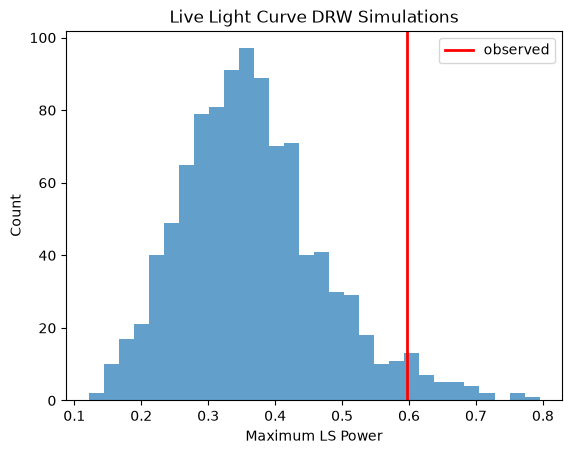

In [27]:
plt.hist(max_powers,bins=30,alpha=.7)
plt.axvline(best_power,c='r',lw=2,label='observed')
plt.xlabel('Maximum LS Power');plt.ylabel('Count')
plt.title('Live Light Curve DRW Simulations')
plt.legend()

**ANSWER (the criterion first, then the result):**

In this dataset according to my rules there is evidence for a period because the empirical p-value is 3.7% which is less that 5%. The main difference about this sampling is that there is so much more data, 7.4 years of observations vs my samples 2.6 years. This longer time period would allow for a better contraint over $\tau$ and more repititions of any period present in the data. The period that was picked out from Lomb Scargle as the best is 1343 days which is larger than my entire sample lightcurve. With one more week of time I would try to get a spectroscopic observation to see of I can see the two objects as a spectroscopic binary.

## Part 6: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 2 and Part 3 numbers, and what failure would have looked like for each. One to consider: generate a synthetic DRW light curve with a $\sigma$ and $\tau$ you choose, at your epochs and errors, with and without a planted sinusoid; run your whole pipeline on it; see whether the 68% intervals contain what you put in and whether Part 3 finds the sinusoid and finds nothing when there is none. One realisation is a spot check, not a calibration: say how many you would need.


**AI-USE APPENDIX:**

I used a custom agent on microsoft copilot. The largest error is that when producing code to copy sometimes the markdown tab would be contaminated by a bunch of * in random places. I have seen this error before and it is more annoying than anuthing. I used the AI to write code when I couldn't figure out how to do it myself and to check the code I did write myself If I cam across any errors. I also used the AI to check my understanding of the concepts used and to varify if any claims I make in this lab are correct.

**REFLECTION:**

I try my best to verify my AI results with content from the lecture but If I didn't check the output I could be coding most of this lab incorrectly. Since the AI is my main verification tool I could be in an eco chamber of my own mistakes and have attacked these prompts completely incorectly. One example of this is plotting thethe posterior mean prediction in part 3. I am pretty sure it is correct because it matches what I saw in lecture, but if it isnt my next few parts contain analysis based on that code.

**VERIFICATION PLAN:**

Check on simulated data: Generate a synthetic light curve and see if my pipeline can retain the true values I entered. While this tests is only a spot check, a true convergence test would need to run at least 100 times and my pipline is too computationally expensive. For this spot check I need to return a value with error bars that is at least near the true value to pass

Check Period Claim method: Generate a DRW lightcurve without a sinusuadal and see if I can still determine that no periocity is detected, This fails if my rule rules that there is a significant period

MCMC convergence check: Check that my chains converged and that the autocorrelation time is shorter than the chain.


Injected μ = 20
Recovered μ = 19.74824618278459
Injected σ = 0.4
Recovered σ = 0.4212099652222655
Injected τ = 500
Recovered τ = 619.0448957919272


Text(0, 0.5, 'g mag')

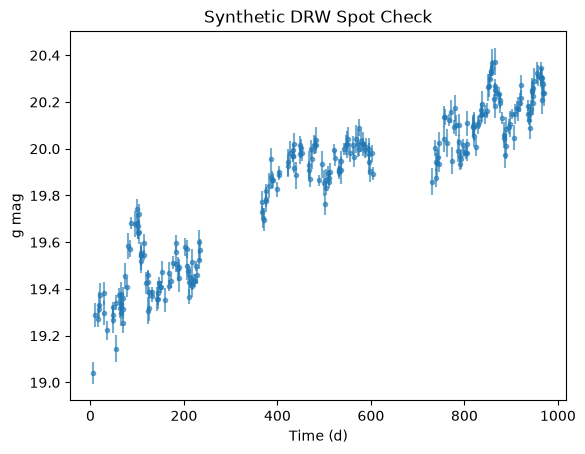

In [28]:
rng = np.random.default_rng(10272026)

mu_true,sig_true,tau_true = 20,.4,500

dt = np.abs(t[:,None]-t[None,:])
C = sig_true**2*np.exp(-dt/tau_true)

ysim = mu_true + np.linalg.cholesky(C+1e-10*np.eye(len(t)))@rng.normal(size=len(t))
ysim += rng.normal(0,e)

results = []

for sig0 in [0.03,0.1,0.3,1.0]:
    for tau0 in [20,100,500,2000]:

        p0 = np.array([np.mean(ysim),np.log(sig0),np.log(tau0)])

        res = minimize(neg_log_likelihood,p0,args=(t,ysim,e),method='Nelder-Mead')

        if res.success:
            results.append((log_likelihood(res.x,t,ysim,e),res.x))

results.sort(key=lambda x:x[0],reverse=True)

best_sim = results[0][1]

print('Injected μ =',mu_true)
print('Recovered μ =',best_sim[0])

print('Injected σ =',sig_true)
print('Recovered σ =',np.exp(best_sim[1]))

print('Injected τ =',tau_true)
print('Recovered τ =',np.exp(best_sim[2]))

plt.errorbar(t,ysim,yerr=e,fmt='.',alpha=.6)
plt.title('Synthetic DRW Spot Check');plt.xlabel('Time (d)');plt.ylabel('g mag')

##### Check on simulated data

This check on simulated data, while only a spot check, did pass. My model was able to converge very closely to the true values of $\mu$ and $\sigma$ while still coming close to $\tau$ in context of how hard it was to constrain earlier in my analysis. 

In [33]:
ls = LombScargle(t,ysim,e)

frequency,power = ls.autopower(minimum_frequency=2/T,maximum_frequency=1/20,samples_per_peak=5)

best_power = power.max()

mu_fit, sig_fit, tau_fit = best_sim[0],np.exp(best_sim[1]),np.exp(best_sim[2])

dt = np.abs(t[:,None]-t[None,:])
L = np.linalg.cholesky(sig_fit**2*np.exp(-dt/tau_fit)+1e-10*np.eye(len(t)))

max_powers = np.zeros(1000)

for i in range(1000):

    fake = mu_fit + L@rng.normal(size=len(t)) + rng.normal(0,e)

    p = LombScargle(t,fake,e).power(frequency)

    max_powers[i] = p.max()

p_emp = np.mean(max_powers>=best_power)

print('Empirical p-value =',p_emp)

if p_emp<=0.05:
    print('FAIL: false period detected')
else:
    print('PASS: no significant period detected')

Empirical p-value = 0.218
PASS: no significant period detected


My process to determine if a period was significant was able to pass when tested against data that I know has no sinusuadal signal. By having a p value > 5% I was able to show that any period seen in this lightcurve is not significant

mu = 47.697518414499626
lnsig = 52.55993499098449
lntau = 51.98920189141772
chain/tau = 57.077696167519704
PASS: chain appears converged


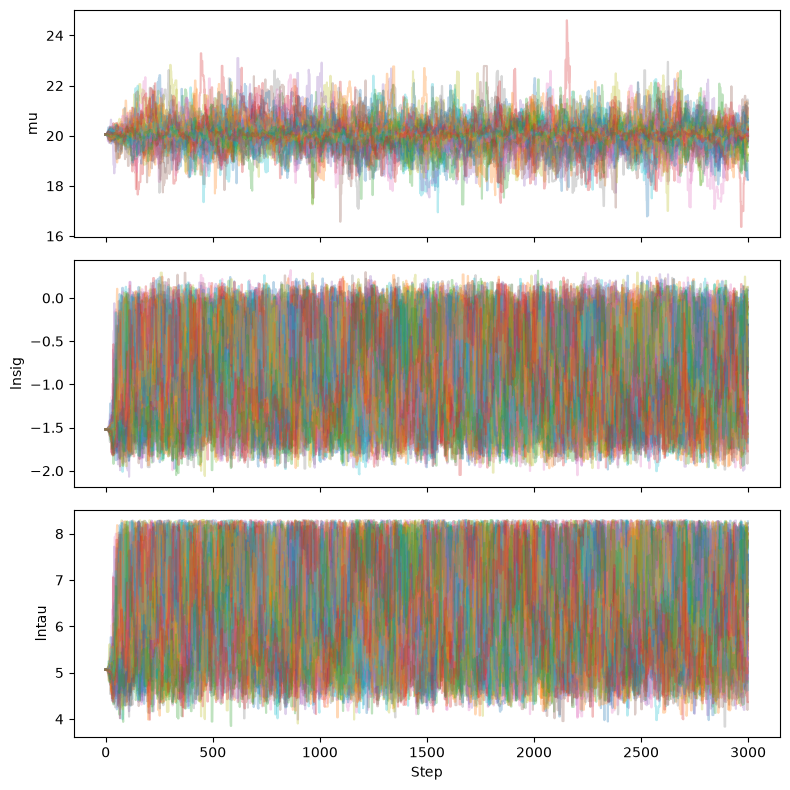

In [34]:
tau = sampler.get_autocorr_time()

for n,x in zip(['mu','lnsig','lntau'],tau):
    print(n,'=',x)

ratio = nsteps/np.max(tau)

print('chain/tau =',ratio)

if ratio>50:
    print('PASS: chain appears converged')
else:
    print('FAIL: chain may be too short')

chain = sampler.get_chain()

fig,ax = plt.subplots(3,1,figsize=(8,8),sharex=True)

for i,n in enumerate(['mu','lnsig','lntau']):
    ax[i].plot(chain[:,:,i],alpha=.3)
    ax[i].set_ylabel(n)

ax[-1].set_xlabel('Step')
plt.tight_layout()

the longest autocorrelation time is 53 steps and the chain lenght is 3000 giving a chain length of ~ 50$\tau$. The trace plots show good mixing and no long-term drift, suggesting convergence.